# Mixture of Gaussians

Testing the mixture of gaussians clustering algorithm which is able to find clusters with hyper-ellipssoid shape.

entropy, kurtosis, crest factor.

test c-means and gaussian

test total_energy calculation, clean up code.

feature selection + numerical studies
(for k-means and c-means, which set of metrics works the best for each.)

1st paper is k-means
2nd paper compares k-means with c-means and gaussian.

then write up and focus on the second paper. dicuss different classification methods

how to test wavelet orders? better representation of transients vs computational cost and cluster separation.

In [1]:
import sys

In [2]:
%matplotlib inline
sys.path.append("..")
import wavelet_transform.utils.training_data as train
import wavelet_transform.postprocess.plotting as plot

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [3]:
pac = -5E5                                  # the amplitude of the sine wave in Pa
frequency = 5E5                  # insonation frequency (Hz)
no_cycle = 20                               # no. of cycles of the sine wave
sampling_rate = 500E6      # sampling rate to generate the time vector
real_sampling_rate = 25E6
tstep = 1. / sampling_rate
tmax = no_cycle / frequency
time = np.arange(0., tmax, tstep) # time vector for computing the sine wave, in seconds
t_plot = time

R_init = 10E-6                  # initial bubble radius in meters
Rdot_init = 0                   # initial bubble's wall velocity in m/s

r_measure = 50*R_init           # distance from the centre of bubble which radiated pressure (acoustic emission from bubble) is calculated over time 

std_noise = 0.001

wavelet = "db20"
levels = 4
mode = "symmetric"

fft_lim = 10 * frequency  # increase value to view more of the fft plots

### Training data

Run bubble dynamics over a range of frequencies and intensities to generate a larger array of training data.

In [4]:

wpt_df = None
for frequency in [i * 1E5 for i in range(8, 10)]:
    for pac in [-i * 1E4 for i in range(1, 20)]:
        data = train.generate_data(R_init, Rdot_init, frequency, pac, time, tstep, r_measure)
        if max(data) > 70 or np.isnan(data).any():  # filter out failed dynamics model computations
            continue
        data = (data - np.mean(data))/np.std(data)
        data += np.random.normal(0, std_noise, size=len(data))

        # data = np.random.normal(0, std_noise, size=len(data))

        # plt.plot(data)
        # plt.title(f"Frequency: {frequency}, pac: {pac}")
        # plt.show()
        step = int(sampling_rate/real_sampling_rate)
        training_data = train.generate_training_data(
            data[::step], levels, wavelet, mode, min_energy=0.005, include_low_energy=1
        )
        if wpt_df is None:
            wpt_df = training_data
        else:
            wpt_df = pd.concat([wpt_df, training_data], ignore_index=True)

# Add noise samples
add_noise = .1  # 1/10 of the dataset is noise
n = wpt_df.shape[0]
n_noise_samples = int(n * add_noise / (1 - add_noise))

for i in range(n_noise_samples):
    noise = np.random.normal(0, std_noise, size=len(data))
    training_data = train.generate_training_data(noise[::step], levels, wavelet, mode)
    wpt_df= pd.concat([wpt_df, training_data], ignore_index=True)

### Training

Train the mixture of gaussians on the generated data

In [6]:
from sklearn.preprocessing import StandardScaler
from sklearn.mixture import GaussianMixture

# Get data
wpt_df
# ["log energy", "crest factor", "spectral entropy"]
classifying_metrics = ["log energy", "level entropy", "kurtosis"]
data_train = wpt_df[classifying_metrics]

# Standardise data
scaler = StandardScaler()
data_train_normalised = scaler.fit_transform(data_train)

# Parameters for mixture of gaussians
no_clusters = 4

# Mixture of gaussians clustering
gm = GaussianMixture(no_clusters)
labels = gm.fit_predict(data_train_normalised)

# Cluster centres
centers = scaler.inverse_transform(gm.means_)
print("centers:", centers)

# Hard cluster assignments
for i in range(no_clusters):
    print(f"label {i} count:", list(labels).count(i))

centers: [[-4.01544530e+00  6.10487179e-01  3.04086979e+00]
 [ 2.77240643e+00  3.45843775e+00  2.21564382e+00]
 [-7.98383756e-01  5.05699437e-03  3.35809092e+00]
 [ 4.52942567e-02  1.48355769e-02  1.36638568e+01]]
label 0 count: 1072
label 1 count: 76
label 2 count: 450
label 3 count: 82


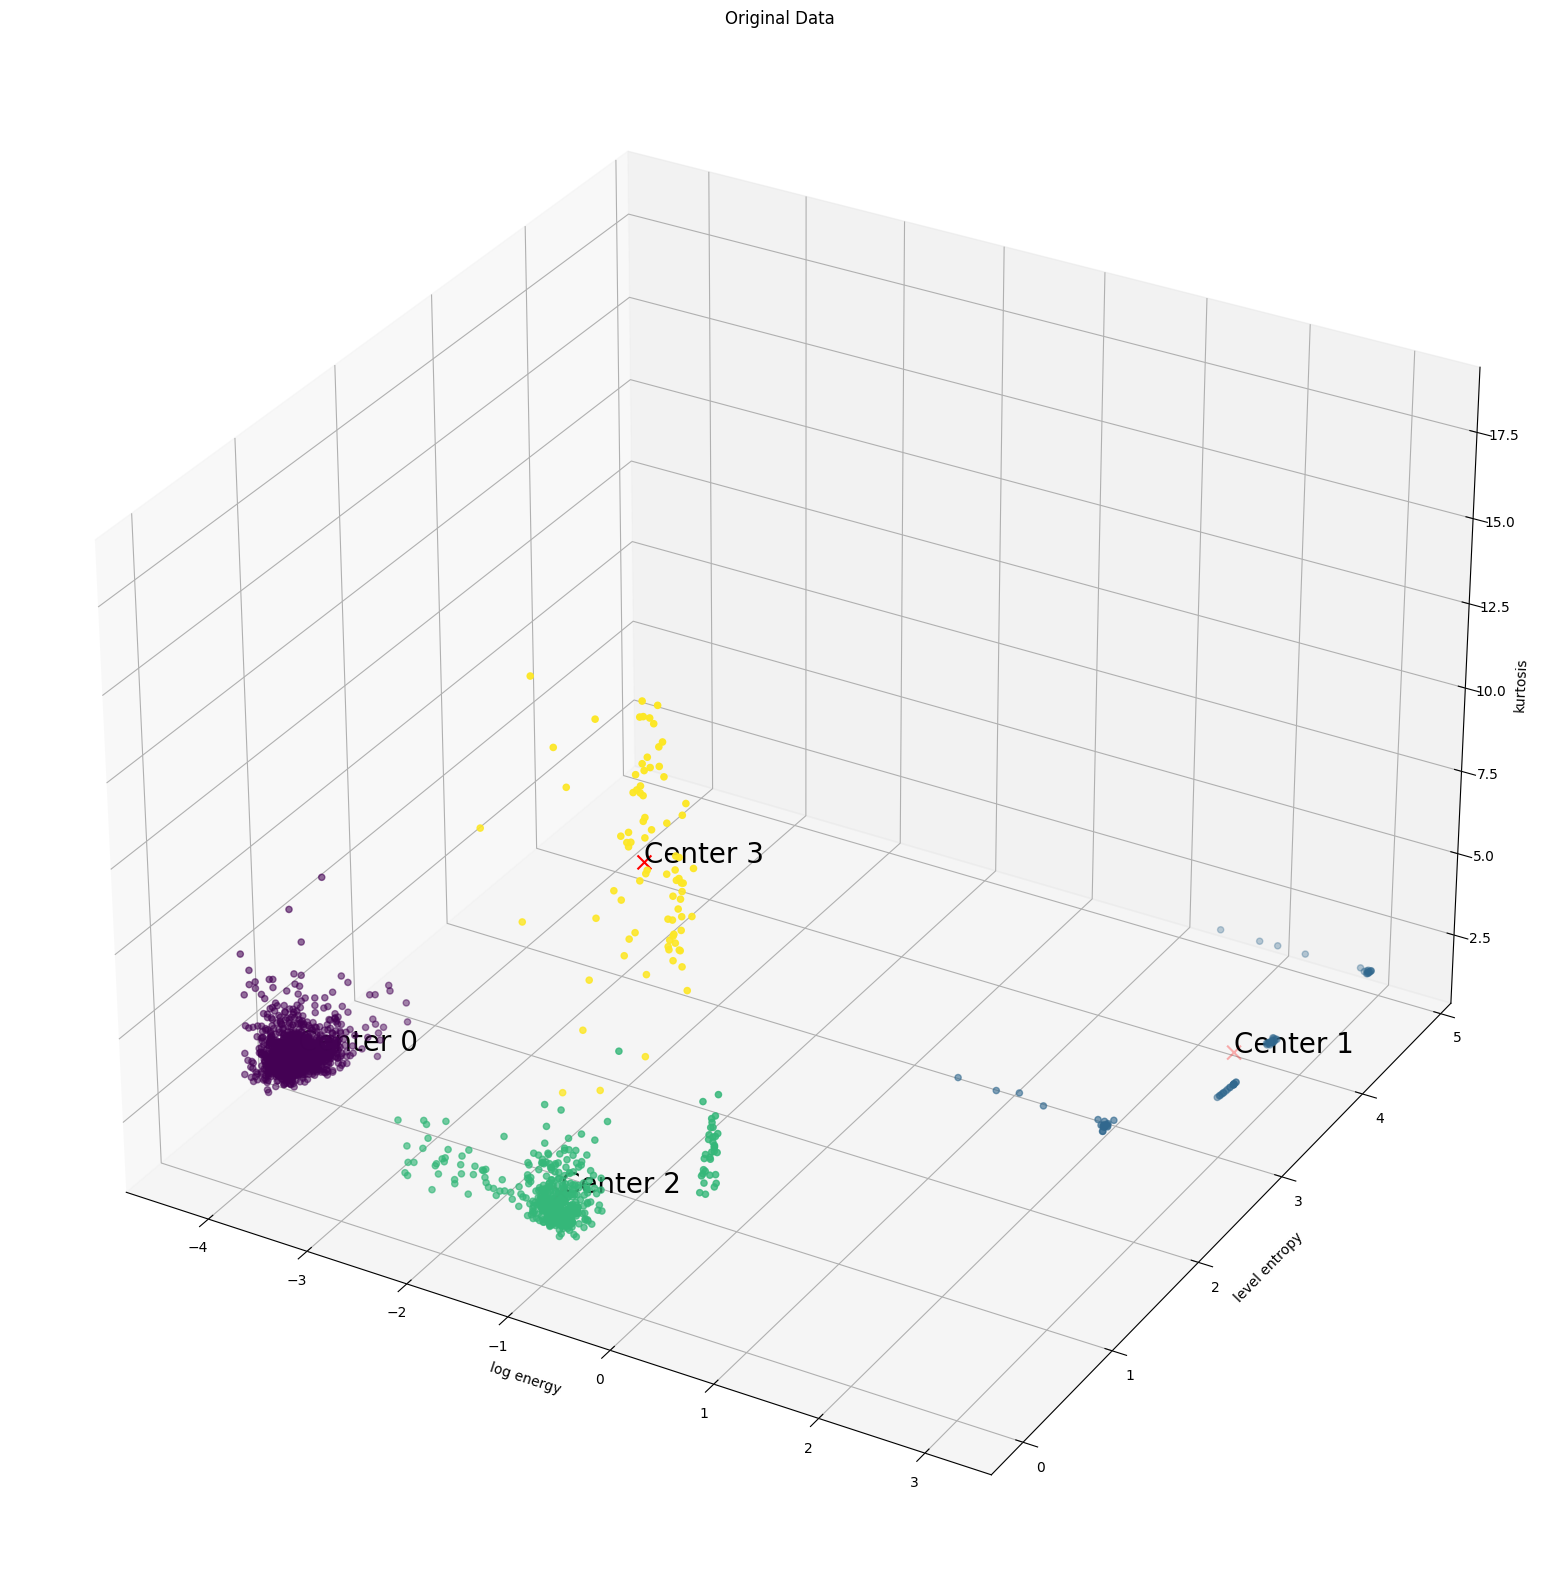

In [7]:
fig = plt.figure(figsize=(20, 20))
ax = fig.add_subplot(111, projection="3d")

title = "Original Data"

data_scatter = data_train.values.tolist()
centers_scatter = centers
color_map_labels = labels

# Plot data points
data_plot = ax.scatter(
    [point[0] for point in data_scatter],
    [point[1] for point in data_scatter],
    [point[2] for point in data_scatter],
    c=color_map_labels
)

# Plot cluster centers after data points
center_plot = ax.scatter(
    centers_scatter[:, 0],
    centers_scatter[:, 1],
    centers_scatter[:, 2],
    c="red",
    marker="x",
    s=100,
)

# Annotate cluster centers with their positions
for i, center in enumerate(centers_scatter):
    ax.text(center[0], center[1], center[2], f'Center {i}', color='black', fontsize=20)

ax.set_xlabel(data_train.columns[0])
ax.set_ylabel(data_train.columns[1])
ax.set_zlabel(data_train.columns[2])
ax.set_title(title)

plt.show()

### Classifying new data points

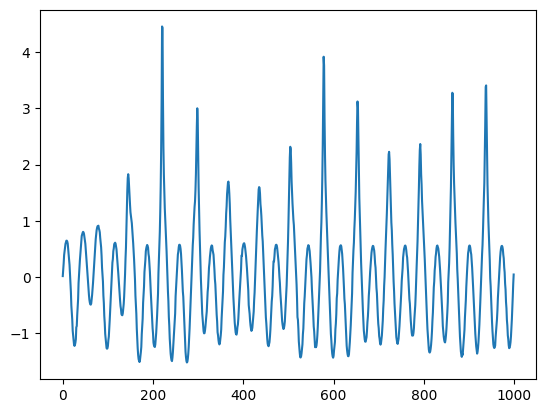

In [8]:
frequency = 7E5
pac = -2E5

min_energy = 0  # Only nodes with energy at least min_energy * total_energy will be considered

data = train.generate_data(R_init, Rdot_init, frequency, pac, time, tstep, r_measure)
data = (data - np.mean(data)) / np.std(data)
data += np.random.normal(0, std_noise, len(data))
data = data[::step]

new_wpt_df, new_tr_ob = train.generate_training_data(
    data, 
    levels,
    wavelet, 
    mode,
    min_energy=min_energy,
    include_tr_ob=True
)

plt.plot(data)
plt.show()

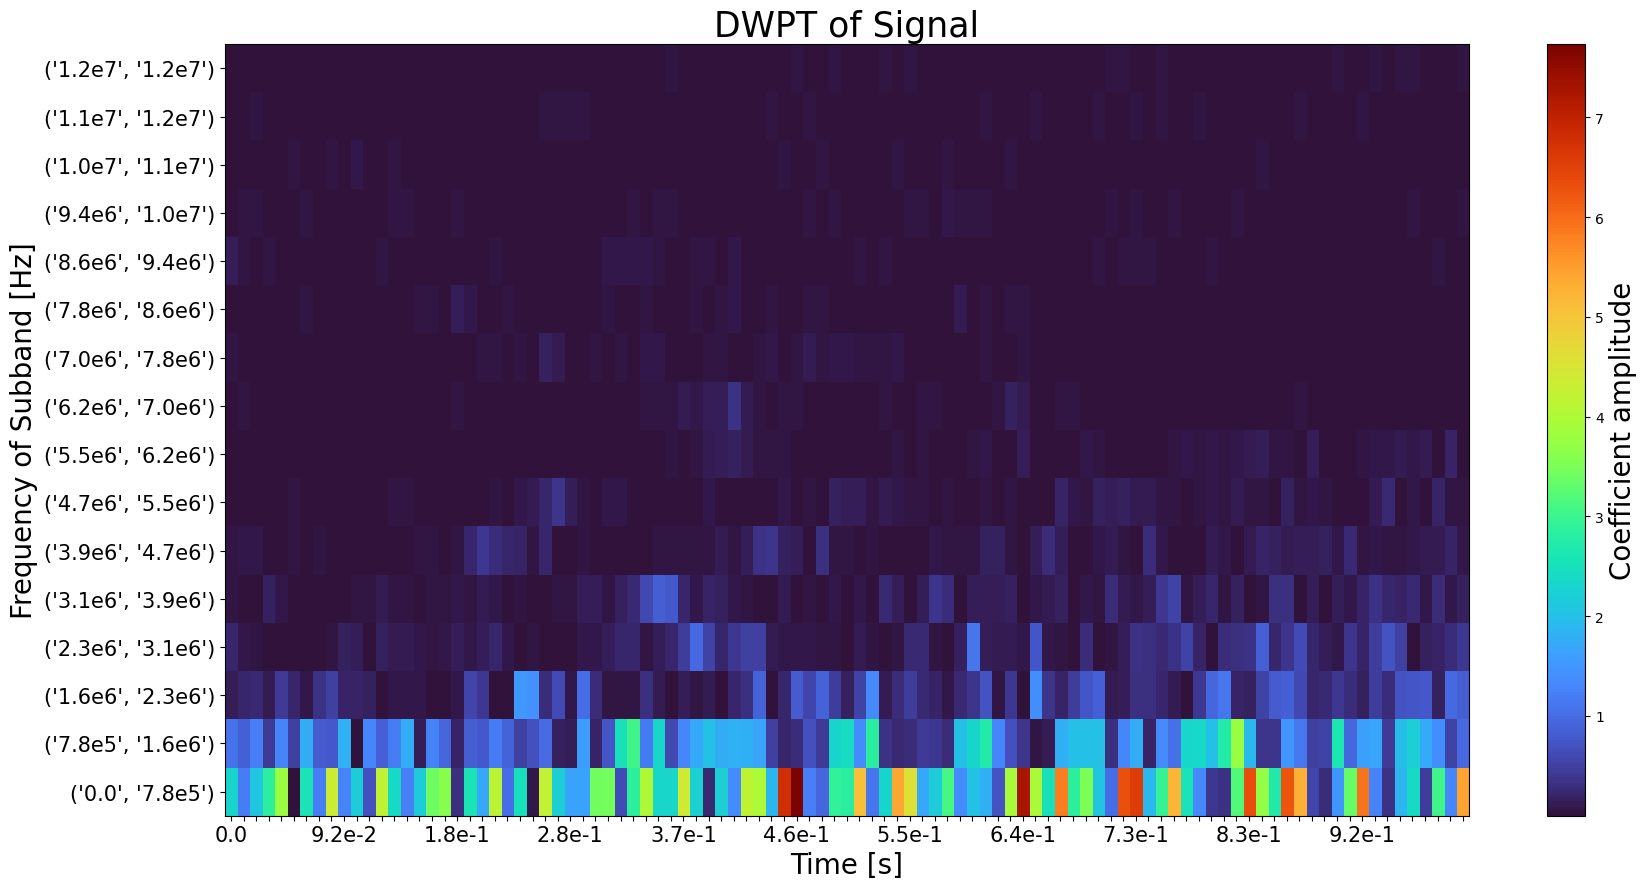

In [9]:
new_tr_ob.calc_frequencies(real_sampling_rate)
plot.heisenberg(new_tr_ob)

In [10]:
# New testing data from signal
new_entry = new_wpt_df[classifying_metrics]

# Standardize the new entry using the same scaler
new_entry_normalized = scaler.transform(new_entry)

# New labels
new_labels = gm.predict(new_entry_normalized)

# Display the predicted results
print("Predicted hard cluster assignment:", labels)

Predicted hard cluster assignment: [1 1 2 ... 0 0 0]


Reconstructed nodes by group:


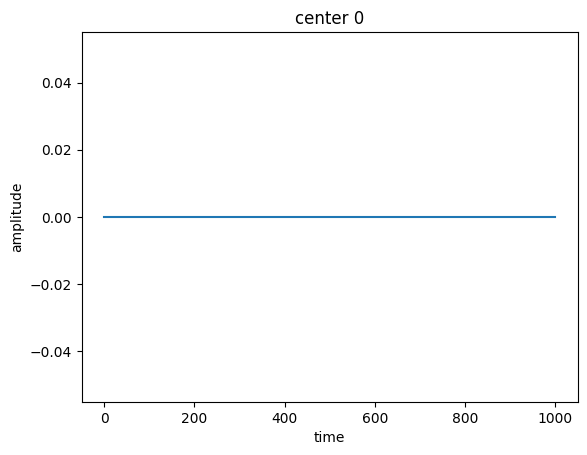

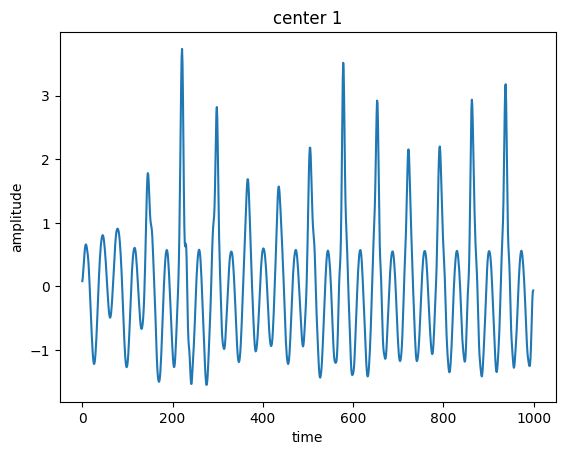

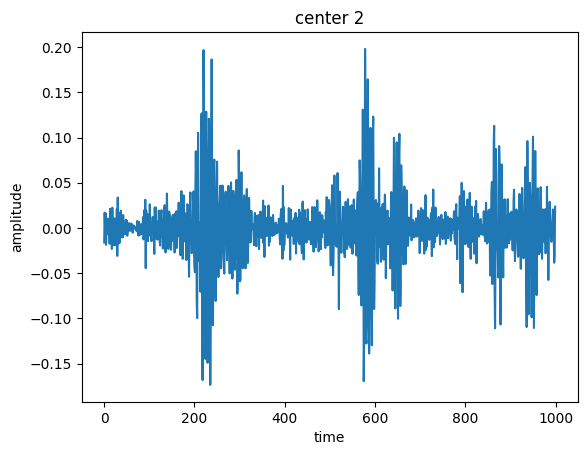

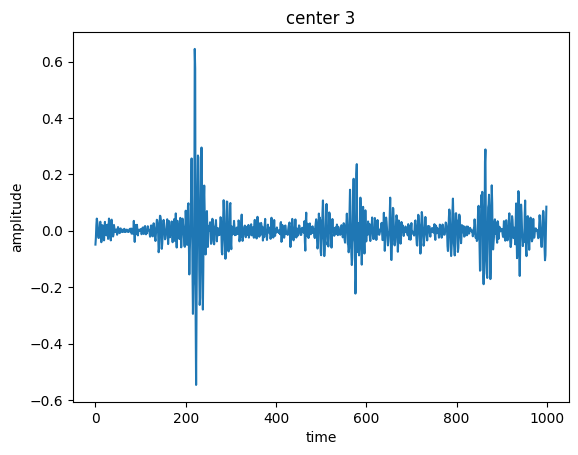

In [11]:
plot.plot_reconstructions_by_group(new_tr_ob, new_labels, no_clusters, order="freq")